In [1]:
import os, glob, time
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models

DATA_DIR = r"C:\Users\om\OneDrive\Desktop\exotrac_paper\processed_data"
SAVE_DIR = r"C:\Users\om\OneDrive\Desktop\exotrac_paper\checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

IMG_SIZE = 256
MAX_KPTS = 8
BATCH_SIZE = 8
EPOCHS = 60
LR = 1e-3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using Device:", DEVICE, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

Using Device: cuda | GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [4]:
class ContainerPoseSegDataset(Dataset):
    def __init__(self, split_dir, augment=False):
        files = sorted(glob.glob(os.path.join(split_dir, "*.npz")))
        self.augment = augment
        self.samples = []
        mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

        for f in files:
            d = np.load(f)
            orig_h = d["sem_mask"].shape[0]
            scale = IMG_SIZE / float(orig_h)

            img = torch.from_numpy(d["image"].astype(np.float32) / 255.0).permute(2, 0, 1).unsqueeze(0)
            img = F.interpolate(img, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False).squeeze(0).permute(1, 2, 0).numpy()
            img = img[:, :, ::-1].copy()

            sem = torch.from_numpy(d["sem_mask"].astype(np.float32)).unsqueeze(0).unsqueeze(0)
            sem = F.interpolate(sem, size=(IMG_SIZE, IMG_SIZE), mode="nearest").squeeze().long().numpy()

            vf = torch.from_numpy(d["vec_field"].astype(np.float32)).unsqueeze(0)
            vf = F.interpolate(vf, size=(IMG_SIZE, IMG_SIZE), mode="bilinear", align_corners=False).squeeze(0).numpy()

            vm = torch.from_numpy(d["vec_mask"].astype(np.float32)).unsqueeze(0)
            vm = F.interpolate(vm, size=(IMG_SIZE, IMG_SIZE), mode="nearest").squeeze(0).numpy()

            kpts = d["kpts"].astype(np.float32).copy()
            valid = kpts[:, 0] >= 0
            kpts[valid] *= scale

            self.samples.append((img, sem, vf, vm, kpts, mean, std))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img, sem_mask, vec_field, vec_mask, kpts, mean, std = self.samples[idx]
        if self.augment and np.random.rand() < 0.5:
            img = np.clip(img * np.random.uniform(0.8, 1.2), 0.0, 1.0)
        img = np.transpose((img - mean) / std, (2, 0, 1))
        return (
            torch.from_numpy(img),
            torch.from_numpy(sem_mask),
            torch.from_numpy(vec_field),
            torch.from_numpy(vec_mask),
            torch.from_numpy(kpts),
        )

class ResNet50FPNPoseNet(nn.Module):
    def __init__(self, num_classes=2, num_kpts=8):
        super().__init__()
        backbone = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        self.stem = nn.Sequential(backbone.conv1, backbone.bn1, backbone.relu, backbone.maxpool)
        self.layer1, self.layer2, self.layer3, self.layer4 = backbone.layer1, backbone.layer2, backbone.layer3, backbone.layer4

        for p in self.stem.parameters(): p.requires_grad = False
        for p in self.layer1.parameters(): p.requires_grad = False

        self.lat1 = nn.Sequential(nn.Conv2d(256, 64, 1), nn.BatchNorm2d(64), nn.ReLU(inplace=True))
        self.lat2 = nn.Sequential(nn.Conv2d(512, 64, 1), nn.BatchNorm2d(64), nn.ReLU(inplace=True))
        self.lat3 = nn.Sequential(nn.Conv2d(1024, 64, 1), nn.BatchNorm2d(64), nn.ReLU(inplace=True))
        self.lat4 = nn.Sequential(nn.Conv2d(2048, 64, 1), nn.BatchNorm2d(64), nn.ReLU(inplace=True))

        self.up1 = nn.Sequential(nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True))
        self.up2 = nn.Sequential(nn.ConvTranspose2d(128, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(inplace=True))

        self.seg_head = nn.Conv2d(128, num_classes, kernel_size=1)
        self.vec_head = nn.Conv2d(128, num_kpts * 2, kernel_size=1)

    def forward(self, x):
        c1 = self.layer1(self.stem(x))
        c2 = self.layer2(c1)
        c3 = self.layer3(c2)
        c4 = self.layer4(c3)

        p1 = self.lat1(c1)
        p2 = F.interpolate(self.lat2(c2), size=p1.shape[2:], mode="bilinear", align_corners=False)
        p3 = F.interpolate(self.lat3(c3), size=p1.shape[2:], mode="bilinear", align_corners=False)
        p4 = F.interpolate(self.lat4(c4), size=p1.shape[2:], mode="bilinear", align_corners=False)

        feat = self.up2(self.up1(torch.cat([p1, p2, p3, p4], dim=1)))
        return self.seg_head(feat), self.vec_head(feat)

class PaperVotingLoss(nn.Module):
    def __init__(self, img_size=IMG_SIZE, num_kpts=8):
        super().__init__()
        self.num_kpts = num_kpts
        ys, xs = torch.meshgrid(torch.arange(img_size), torch.arange(img_size), indexing="ij")
        self.register_buffer("xs", xs.float())
        self.register_buffer("ys", ys.float())

    def forward(self, seg_logits, vec_pred, sem_mask, vec_gt, vec_mask, kpts, lam1=1.0, lam2=1e-3):
        l_seg = F.cross_entropy(seg_logits, sem_mask)
        B, _, H, W = vec_pred.shape
        vp = vec_pred.view(B, self.num_kpts, 2, H, W)
        vp_unit = vp / (torch.norm(vp, dim=2, keepdim=True) + 1e-6)
        vg = vec_gt.view(B, self.num_kpts, 2, H, W)
        vm = vec_mask.unsqueeze(2)

        l_vf = F.smooth_l1_loss(vp_unit * vm, vg * vm, reduction="sum") / (vm.sum() * 2.0 + 1e-6)

        vx, vy = vp_unit[:, :, 0], vp_unit[:, :, 1]
        px, py = self.xs.view(1, 1, H, W), self.ys.view(1, 1, H, W)
        kx, ky = kpts[:, :, 0].view(B, self.num_kpts, 1, 1), kpts[:, :, 1].view(B, self.num_kpts, 1, 1)

        valid_kpt = (kpts[:, :, 0] >= 0).float().view(B, self.num_kpts, 1, 1) * vec_mask
        dist_perp = torch.abs(vx * (ky - py) - vy * (kx - px)) / float(H)
        l_pv = (dist_perp * valid_kpt).sum() / (valid_kpt.sum() + 1e-6)

        return lam1 * l_seg + l_vf + lam2 * l_pv

In [4]:
EPOCHS = 50
BATCH_SIZE = 16

train_ds = ContainerPoseSegDataset(os.path.join(DATA_DIR, "train"), augment=True)
val_ds = ContainerPoseSegDataset(os.path.join(DATA_DIR, "valid"), augment=False)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

model = ResNet50FPNPoseNet(num_classes=2, num_kpts=MAX_KPTS).to(DEVICE)
criterion = PaperVotingLoss(img_size=IMG_SIZE, num_kpts=MAX_KPTS).to(DEVICE)
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=2e-3)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=15, gamma=0.5)
scaler = torch.amp.GradScaler("cuda")

best_val_loss = float("inf")

for epoch in range(1, EPOCHS + 1):
    t_ep = time.time()
    model.train()
    lam2 = 1e-3 + (1e-2 - 1e-3) * (epoch / EPOCHS)
    tr_loss = 0.0

    for imgs, masks, vecs, vmasks, kpts in train_loader:
        imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
        vecs, vmasks, kpts = vecs.to(DEVICE), vmasks.to(DEVICE), kpts.to(DEVICE)

        optimizer.zero_grad()
        with torch.amp.autocast("cuda"):
            seg_out, vec_out = model(imgs)
            loss = criterion(seg_out, vec_out, masks, vecs, vmasks, kpts, lam1=1.0, lam2=lam2)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        tr_loss += loss.item()

    scheduler.step()
    tr_loss /= len(train_loader)

    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for imgs, masks, vecs, vmasks, kpts in val_loader:
            imgs, masks = imgs.to(DEVICE), masks.to(DEVICE)
            vecs, vmasks, kpts = vecs.to(DEVICE), vmasks.to(DEVICE), kpts.to(DEVICE)
            with torch.amp.autocast("cuda"):
                seg_out, vec_out = model(imgs)
                loss = criterion(seg_out, vec_out, masks, vecs, vmasks, kpts, lam1=1.0, lam2=lam2)
            val_loss += loss.item()
    val_loss /= max(1, len(val_loader))

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), os.path.join(SAVE_DIR, "best_paper_model.pth"))

    print(f"Epoch [{epoch:02d}/{EPOCHS}] ({time.time()-t_ep:.1f}s) | Train: {tr_loss:.4f} | Val: {val_loss:.4f}")

print(f"Done! Best Val Loss: {best_val_loss:.4f}")

Epoch [01/50] (5.3s) | Train: 0.7744 | Val: 1.1370
Epoch [02/50] (4.8s) | Train: 0.3984 | Val: 0.4059
Epoch [03/50] (4.7s) | Train: 0.3197 | Val: 0.4085
Epoch [04/50] (4.8s) | Train: 0.3025 | Val: 0.3324
Epoch [05/50] (4.5s) | Train: 0.2668 | Val: 0.3448
Epoch [06/50] (4.5s) | Train: 0.2635 | Val: 0.3326
Epoch [07/50] (4.6s) | Train: 0.2552 | Val: 0.3333
Epoch [08/50] (4.6s) | Train: 0.2529 | Val: 0.3375
Epoch [09/50] (4.6s) | Train: 0.2512 | Val: 0.3959
Epoch [10/50] (4.9s) | Train: 0.2471 | Val: 0.3267
Epoch [11/50] (4.7s) | Train: 0.2166 | Val: 0.2713
Epoch [12/50] (5.0s) | Train: 0.1709 | Val: 0.2245
Epoch [13/50] (4.8s) | Train: 0.1563 | Val: 0.2201
Epoch [14/50] (4.9s) | Train: 0.1530 | Val: 0.2305
Epoch [15/50] (4.9s) | Train: 0.1441 | Val: 0.2075
Epoch [16/50] (5.0s) | Train: 0.1207 | Val: 0.1940
Epoch [17/50] (5.0s) | Train: 0.1033 | Val: 0.1878
Epoch [18/50] (5.1s) | Train: 0.0863 | Val: 0.1703
Epoch [19/50] (4.7s) | Train: 0.0764 | Val: 0.1731
Epoch [20/50] (4.7s) | Train: 0

In [6]:
import os
print(os.listdir("checkpoints"))

['best_clean_4kpt.pth', 'best_corner_net.pth', 'best_paper_model.pth', 'last_paper_model.pth', 'sharp_pvnet.pth', 'stable_corner_net.pth']


In [1]:
import os, glob

ROBOFLOW_DIR = "."
for split in ["train", "valid", "test"]:
    imgs = glob.glob(os.path.join(ROBOFLOW_DIR, split, "images", "*.*"))
    lbls = glob.glob(os.path.join(ROBOFLOW_DIR, split, "labels", "*.txt"))
    print(f"{split}: {len(imgs)} images, {len(lbls)} labels")

sample_lbl = sorted(glob.glob(os.path.join(ROBOFLOW_DIR, "train", "labels", "*.txt")))[0]
with open(sample_lbl) as f:
    print("Sample label line:", f.readline().strip()[:120])

train: 167 images, 167 labels
valid: 46 images, 46 labels
test: 23 images, 23 labels
Sample label line: 0 0.2013888888888889 0.7725694444444444 0.2065972222222222 0.7777777777777778 0.21875 0.7760416666666666 0.2413194444444


Running 512x512 upgrade on device: cuda
Built 167 512x512 .npz samples for [train]
Built 46 512x512 .npz samples for [valid]
Built 23 512x512 .npz samples for [test]
Warm-started from: checkpoints/stable_corner_net_finetuned.pth

Starting 25-epoch 512x512 fine-tuning...
Epoch 01/25 | Train Loss: 0.8676 | Val Loss: 0.9071  <-- saved best 512
Epoch 02/25 | Train Loss: 0.6437 | Val Loss: 0.8572  <-- saved best 512
Epoch 03/25 | Train Loss: 0.5712 | Val Loss: 0.8384  <-- saved best 512
Epoch 04/25 | Train Loss: 0.4975 | Val Loss: 0.8203  <-- saved best 512
Epoch 05/25 | Train Loss: 0.4537 | Val Loss: 0.8132  <-- saved best 512
Epoch 06/25 | Train Loss: 0.4314 | Val Loss: 0.8237
Epoch 07/25 | Train Loss: 0.3970 | Val Loss: 0.8053  <-- saved best 512
Epoch 08/25 | Train Loss: 0.3904 | Val Loss: 0.8122
Epoch 09/25 | Train Loss: 0.3541 | Val Loss: 0.7838  <-- saved best 512
Epoch 10/25 | Train Loss: 0.3431 | Val Loss: 0.8025
Epoch 11/25 | Train Loss: 0.3221 | Val Loss: 0.8065
Epoch 12/25 | Tra

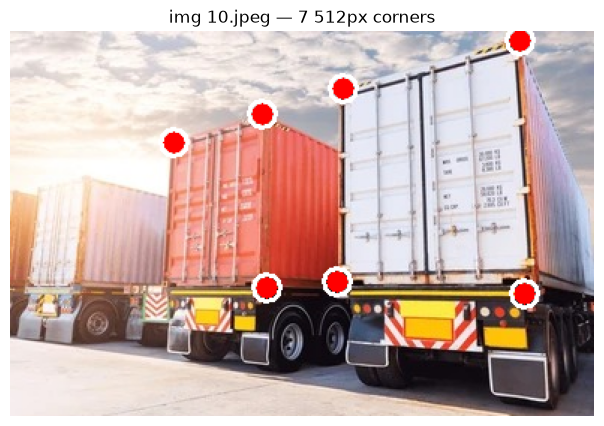

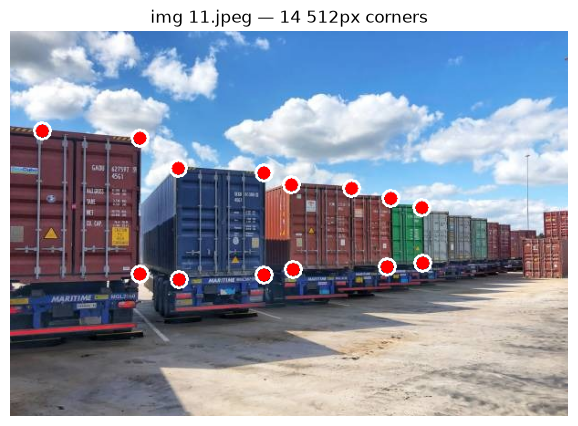

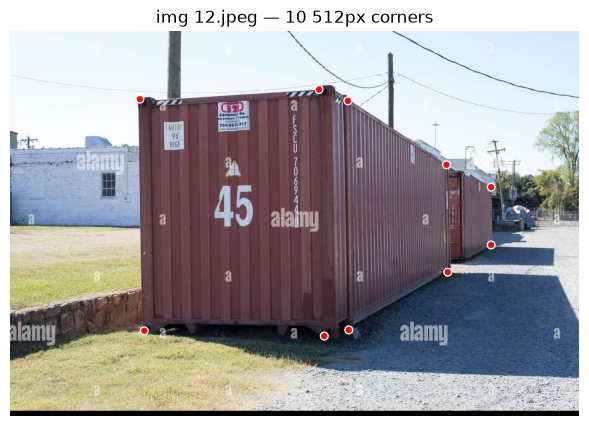

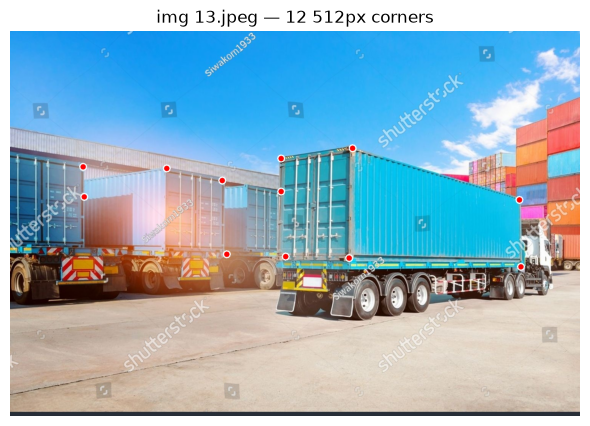

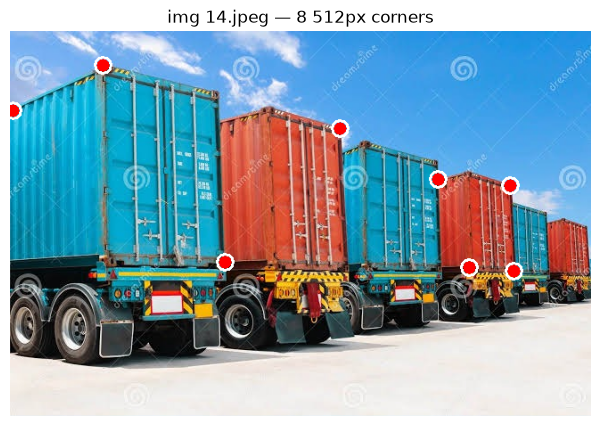

...

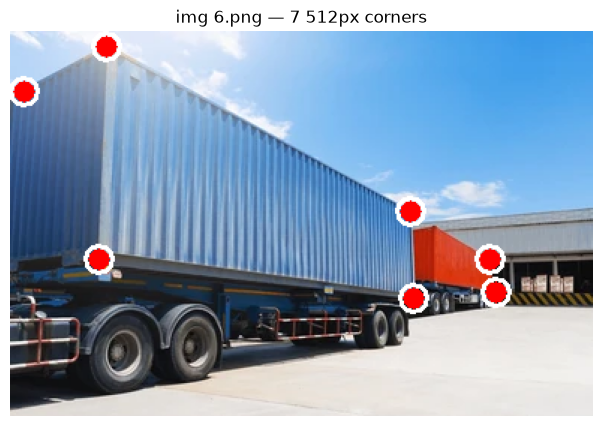

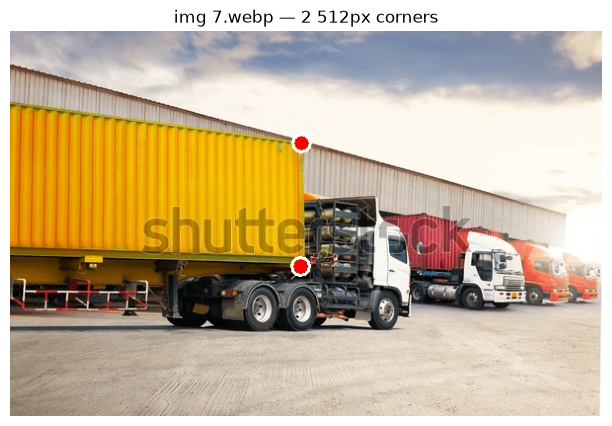

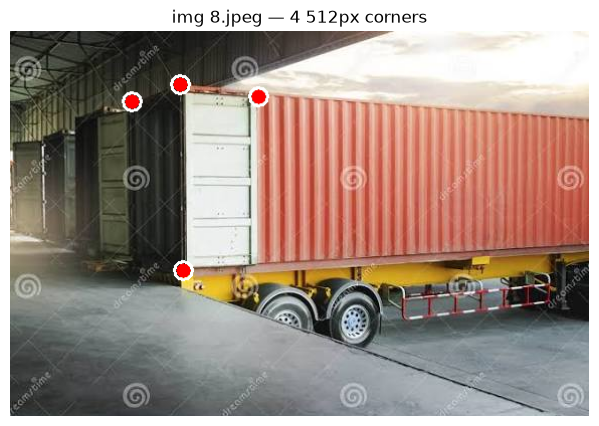

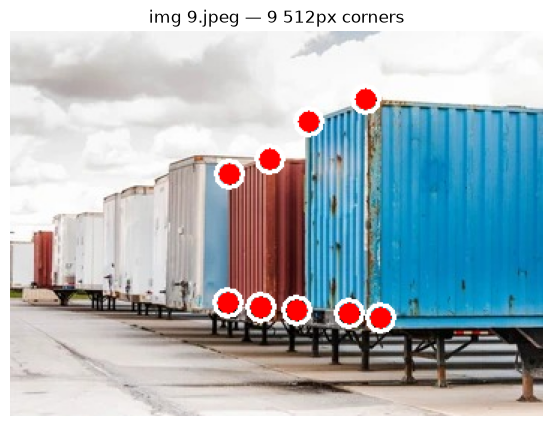

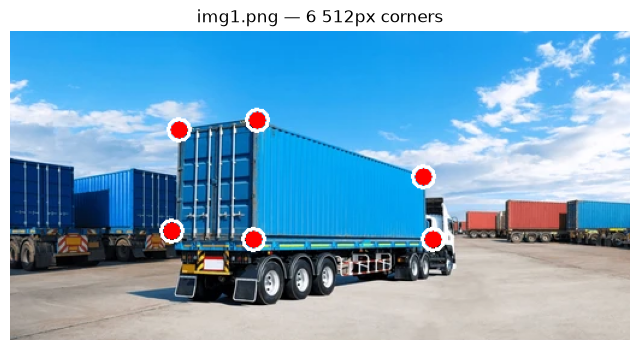

In [7]:
import os, glob, cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import matplotlib.pyplot as plt

IMG_SIZE = 512
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running 512x512 upgrade on device:", DEVICE)

# ==========================================
# STEP 1: Build Clean 512x512 .npz Dataset (Filtering Collinear Edge Vertices)
# ==========================================
OUT_NPZ_DIR = "processed_data_512"

def filter_true_polygon_corners(pts, angle_thresh_deg=166.0, margin=4.0, size=512):
    """Keeps only sharp geometric corners of a polygon, dropping straight-edge midpoints and frame-border points."""
    n = len(pts)
    if n < 3:
        return []
    corners = []
    for i in range(n):
        p_prev = pts[(i - 1) % n]
        p_curr = pts[i]
        p_next = pts[(i + 1) % n]

        x, y = p_curr
        # Ignore dummy points clipped on the image frame edge
        if x <= margin or x >= size - 1 - margin or y <= margin or y >= size - 1 - margin:
            continue

        v1 = p_prev - p_curr
        v2 = p_next - p_curr
        n1, n2 = np.linalg.norm(v1), np.linalg.norm(v2)
        if n1 < 1e-3 or n2 < 1e-3:
            continue

        cos_ang = np.clip(np.dot(v1, v2) / (n1 * n2), -1.0, 1.0)
        angle = np.degrees(np.arccos(cos_ang))
        # Only keep vertices where the edge actually bends (rejects ~180 deg straight-line midpoints)
        if angle < angle_thresh_deg:
            corners.append(p_curr.tolist())
    return corners

def make_gaussian_heatmap(kpts, size=512, sigma=4.5):
    hm = np.zeros((size, size), dtype=np.float32)
    yy, xx = np.mgrid[0:size, 0:size]
    for x, y in kpts:
        g = np.exp(-((xx - x) ** 2 + (yy - y) ** 2) / (2 * sigma ** 2))
        hm = np.maximum(hm, g)
    return hm

for split in ["train", "valid", "test"]:
    split_out = os.path.join(OUT_NPZ_DIR, split)
    os.makedirs(split_out, exist_ok=True)
    img_paths = sorted(glob.glob(os.path.join(split, "images", "*.*")))
    count = 0
    for img_p in img_paths:
        stem = os.path.splitext(os.path.basename(img_p))[0]
        lbl_p = os.path.join(split, "labels", stem + ".txt")
        if not os.path.exists(lbl_p):
            continue

        bgr = cv2.imread(img_p)
        if bgr is None:
            continue
        rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        rgb_512 = cv2.resize(rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)

        mask_512 = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.uint8)
        all_kpts = []

        with open(lbl_p, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 7:
                    continue
                coords = np.array([float(v) for v in parts[1:]], dtype=np.float32).reshape(-1, 2)
                pts_512 = coords * IMG_SIZE
                poly_int = np.round(pts_512).astype(np.int32)
                cv2.fillPoly(mask_512, [poly_int], 1)

                true_corners = filter_true_polygon_corners(pts_512, angle_thresh_deg=166.0, margin=4.0, size=IMG_SIZE)
                all_kpts.extend(true_corners)

        all_kpts = np.array(all_kpts, dtype=np.float32) if len(all_kpts) > 0 else np.zeros((0, 2), dtype=np.float32)
        hm_512 = make_gaussian_heatmap(all_kpts, size=IMG_SIZE, sigma=4.5)

        np.savez_compressed(
            os.path.join(split_out, f"{stem}.npz"),
            image=rgb_512,
            mask=mask_512,
            heatmap=hm_512
        )
        count += 1
    print(f"Built {count} 512x512 .npz samples for [{split}]")

# ==========================================
# STEP 2: 512x512 Dataset & DataLoaders
# ==========================================
class Container512Dataset(Dataset):
    def __init__(self, npz_dir, augment=False):
        self.files = sorted(glob.glob(os.path.join(npz_dir, "*.npz")))
        self.augment = augment
        self.mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
        self.std = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        data = np.load(self.files[idx])
        img = data["image"].copy()
        mask = data["mask"].copy()
        hm = data["heatmap"].copy()

        if self.augment:
            if np.random.rand() < 0.5:
                img = np.ascontiguousarray(img[:, ::-1, :])
                mask = np.ascontiguousarray(mask[:, ::-1])
                hm = np.ascontiguousarray(hm[:, ::-1])
            if np.random.rand() < 0.5:
                alpha = np.random.uniform(0.85, 1.15)
                beta = np.random.uniform(-15, 15)
                img = np.clip(img.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)

        img_t = ((img.astype(np.float32) / 255.0 - self.mean) / self.std).transpose(2, 0, 1)
        return (
            torch.from_numpy(img_t),
            torch.from_numpy(mask).long(),
            torch.from_numpy(hm).unsqueeze(0).float()
        )

train_loader = DataLoader(Container512Dataset(os.path.join(OUT_NPZ_DIR, "train"), augment=True), batch_size=4, shuffle=True)
val_loader = DataLoader(Container512Dataset(os.path.join(OUT_NPZ_DIR, "valid"), augment=False), batch_size=4, shuffle=False)

# ==========================================
# STEP 3: Warm-Start StableCornerNet & Train at 512x512
# ==========================================
class StableCornerNet(nn.Module):
    def __init__(self):
        super().__init__()
        b = models.resnet50(weights=None)
        self.stem0 = nn.Sequential(b.conv1, b.bn1, b.relu)
        self.pool = b.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = b.layer1, b.layer2, b.layer3, b.layer4

        self.lat1 = nn.Sequential(nn.Conv2d(256, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))
        self.lat2 = nn.Sequential(nn.Conv2d(512, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))
        self.lat3 = nn.Sequential(nn.Conv2d(1024, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))
        self.lat4 = nn.Sequential(nn.Conv2d(2048, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))

        self.up1 = nn.Sequential(nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(True))
        self.fuse128 = nn.Sequential(nn.Conv2d(128 + 64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(True))
        self.up2 = nn.Sequential(nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True))

        self.seg_head = nn.Conv2d(64, 2, 1)
        self.hm_head = nn.Sequential(nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(True), nn.Conv2d(32, 1, 1))

    def forward(self, x):
        s0 = self.stem0(x)
        c1 = self.layer1(self.pool(s0))
        c2 = self.layer2(c1); c3 = self.layer3(c2); c4 = self.layer4(c3)
        p1 = self.lat1(c1)
        p2 = F.interpolate(self.lat2(c2), size=p1.shape[2:], mode="bilinear", align_corners=False)
        p3 = F.interpolate(self.lat3(c3), size=p1.shape[2:], mode="bilinear", align_corners=False)
        p4 = F.interpolate(self.lat4(c4), size=p1.shape[2:], mode="bilinear", align_corners=False)
        f128 = self.fuse128(torch.cat([self.up1(torch.cat([p1, p2, p3, p4], dim=1)), s0], dim=1))
        feat = self.up2(f128)
        return self.seg_head(feat), self.hm_head(feat)

net = StableCornerNet().to(DEVICE)
ckpt_path = "checkpoints/stable_corner_net_finetuned.pth" if os.path.exists("checkpoints/stable_corner_net_finetuned.pth") else "checkpoints/stable_corner_net.pth"
net.load_state_dict(torch.load(ckpt_path, map_location=DEVICE))
print(f"Warm-started from: {ckpt_path}")

EPOCHS = 25
optimizer = torch.optim.AdamW(net.parameters(), lr=8e-5, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
seg_criterion = nn.CrossEntropyLoss()

def weighted_hm_loss(logits, target):
    pred = torch.sigmoid(logits)
    weights = 1.0 + 20.0 * target  # stronger focus on sharp 512x512 corner peaks
    return (weights * (pred - target) ** 2).mean()

best_val_loss = float("inf")
CKPT_512 = "checkpoints/stable_corner_net_512.pth"

print("\nStarting 25-epoch 512x512 fine-tuning...")
for epoch in range(1, EPOCHS + 1):
    net.train()
    tr_loss = 0.0
    for imgs, masks, hms in train_loader:
        imgs, masks, hms = imgs.to(DEVICE), masks.to(DEVICE), hms.to(DEVICE)
        optimizer.zero_grad()
        s_out, h_out = net(imgs)
        loss = seg_criterion(s_out, masks) + 30.0 * weighted_hm_loss(h_out, hms)
        loss.backward()
        optimizer.step()
        tr_loss += loss.item() * imgs.size(0)
    scheduler.step()
    tr_loss /= len(train_loader.dataset)

    net.eval()
    val_loss = 0.0
    with torch.no_grad():
        for imgs, masks, hms in val_loader:
            imgs, masks, hms = imgs.to(DEVICE), masks.to(DEVICE), hms.to(DEVICE)
            s_out, h_out = net(imgs)
            loss = seg_criterion(s_out, masks) + 30.0 * weighted_hm_loss(h_out, hms)
            val_loss += loss.item() * imgs.size(0)
    val_loss /= len(val_loader.dataset)

    tag = ""
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(net.state_dict(), CKPT_512)
        tag = "  <-- saved best 512"
    print(f"Epoch {epoch:02d}/{EPOCHS} | Train Loss: {tr_loss:.4f} | Val Loss: {val_loss:.4f}{tag}")

# ==========================================
# STEP 4: High-Res 512x512 Inference + Collinearity Pruning
# ==========================================
def is_collinear_midpoint(pt, kept_pts, line_tol=5.5):
    px, py = pt
    n = len(kept_pts)
    for i in range(n):
        ax, ay = kept_pts[i]
        for j in range(i + 1, n):
            bx, by = kept_pts[j]
            abx, aby = bx - ax, by - ay
            ab_len2 = abx * abx + aby * aby
            if ab_len2 < 1e-4:
                continue
            t = ((px - ax) * abx + (py - ay) * aby) / ab_len2
            if 0.08 < t < 0.92:
                proj_x, proj_y = ax + t * abx, ay + t * aby
                if np.hypot(px - proj_x, py - proj_y) < line_tol:
                    return True
    return False

@torch.no_grad()
def extract_512_corners(seg_logits, hm_prob, thresh=0.28, min_dist=20.0, min_area_ratio=0.008):
    raw_mask = (seg_logits.argmax(dim=1).squeeze().cpu().numpy() > 0).astype(np.uint8)
    clean_mask = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7)))

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(clean_mask, connectivity=8)
    min_pixels = int(IMG_SIZE * IMG_SIZE * min_area_ratio)

    valid_mask = np.zeros_like(clean_mask)
    for cid in range(1, num_labels):
        if stats[cid, cv2.CC_STAT_AREA] >= min_pixels:
            valid_mask[labels == cid] = 1

    valid_mask = cv2.morphologyEx(valid_mask, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (11, 11)))
    mask_t = torch.from_numpy(valid_mask).float().to(hm_prob.device).unsqueeze(0).unsqueeze(0)
    mask_dil = F.max_pool2d(mask_t, kernel_size=13, stride=1, padding=6)
    hm_masked = hm_prob * mask_dil

    local_max = F.max_pool2d(hm_masked, kernel_size=11, stride=1, padding=5)
    local_avg = F.avg_pool2d(hm_masked, kernel_size=11, stride=1, padding=5)
    peaks = (hm_masked == local_max) & (hm_masked > thresh) & ((hm_masked - local_avg) > 0.07)

    ys, xs = torch.where(peaks[0, 0])
    scores = hm_masked[0, 0, ys, xs]
    if len(scores) == 0:
        return np.zeros((0, 2), dtype=np.float32)

    order = torch.argsort(scores, descending=True)
    hm_np = hm_masked[0, 0].cpu().numpy()

    kept = []
    for idx in order:
        x, y = int(xs[idx].item()), int(ys[idx].item())
        x0, x1 = max(0, x - 2), min(IMG_SIZE, x + 3)
        y0, y1 = max(0, y - 2), min(IMG_SIZE, y + 3)
        patch = hm_np[y0:y1, x0:x1]
        gy, gx = np.mgrid[y0:y1, x0:x1]
        w_sum = patch.sum() + 1e-6
        sub_x = float((patch * gx).sum() / w_sum)
        sub_y = float((patch * gy).sum() / w_sum)

        if any(np.hypot(sub_x - kx, sub_y - ky) < min_dist for kx, ky in kept):
            continue
        if is_collinear_midpoint((sub_x, sub_y), kept, line_tol=5.5):
            continue
        kept.append((sub_x, sub_y))

    return np.array(kept, dtype=np.float32)

net.load_state_dict(torch.load(CKPT_512, map_location=DEVICE))
net.eval()

OUTPUT_DIR = "test_random_512_clean"
os.makedirs(OUTPUT_DIR, exist_ok=True)
mean_rgb = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std_rgb = np.array([0.229, 0.224, 0.225], dtype=np.float32)

print("\nRunning 512x512 Inference on test_random/...")
for path in sorted(glob.glob(os.path.join("test_random", "*.*"))):
    bgr = cv2.imread(path)
    if bgr is None:
        continue
    bgr_clean = bgr[:int(bgr.shape[0] * 0.92), :]
    ch, cw = bgr_clean.shape[:2]

    rgb = cv2.cvtColor(bgr_clean, cv2.COLOR_BGR2RGB)
    resized = cv2.resize(rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    tensor = ((resized.astype(np.float32) / 255.0 - mean_rgb) / std_rgb).transpose(2, 0, 1)
    inp = torch.from_numpy(tensor).unsqueeze(0).to(DEVICE)

    s_out, h_logits = net(inp)
    h_prob = torch.sigmoid(h_logits)
    pred_kpts = extract_512_corners(s_out, h_prob, thresh=0.28, min_dist=20.0)

    vis = rgb.copy()
    for x512, y512 in pred_kpts:
        xo = int(round((x512 + 0.5) * cw / IMG_SIZE))
        yo = int(round((y512 + 0.5) * ch / IMG_SIZE))
        cv2.circle(vis, (xo, yo), 7, (255, 0, 0), -1)
        cv2.circle(vis, (xo, yo), 9, (255, 255, 255), 2)

    cv2.imwrite(os.path.join(OUTPUT_DIR, os.path.basename(path)), cv2.cvtColor(vis, cv2.COLOR_RGB2BGR))
    plt.figure(figsize=(8, 5))
    plt.imshow(vis)
    plt.title(f"{os.path.basename(path)} — {len(pred_kpts)} 512px corners")
    plt.axis("off")
    plt.show()

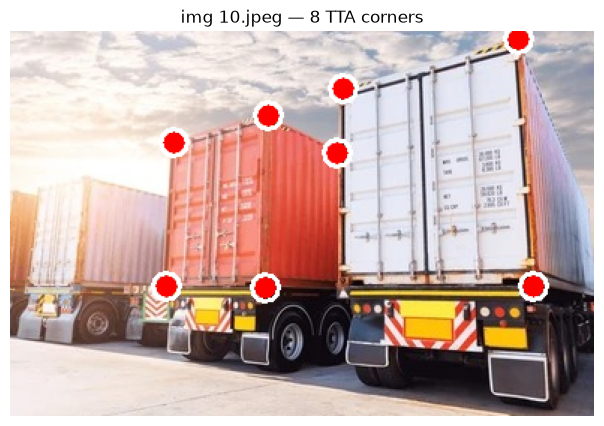

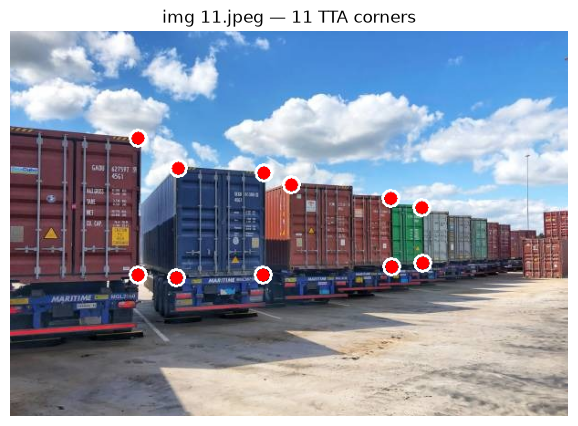

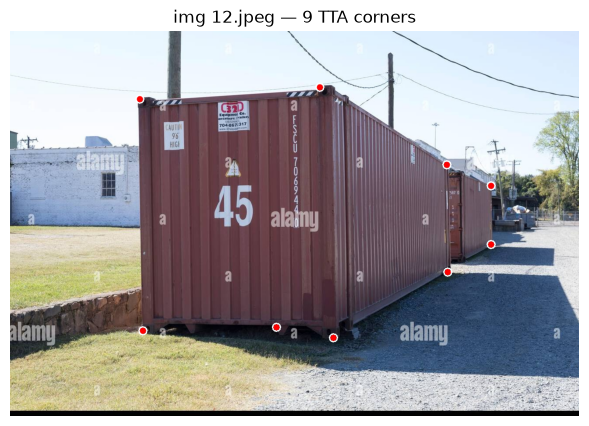

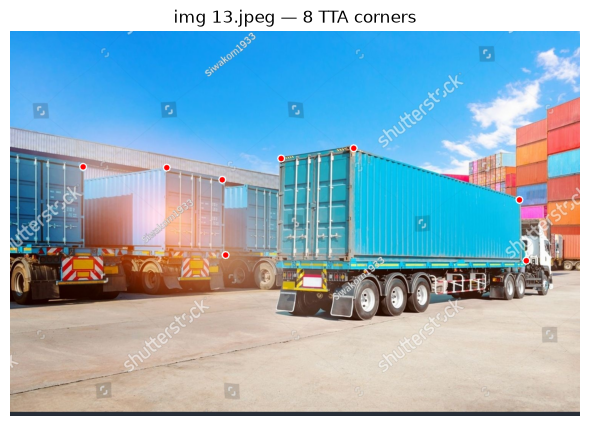

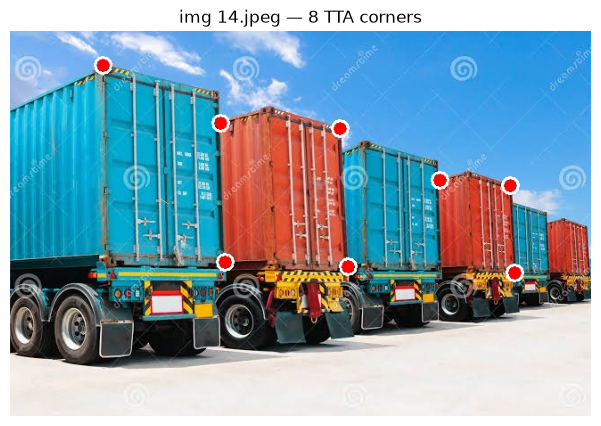

...

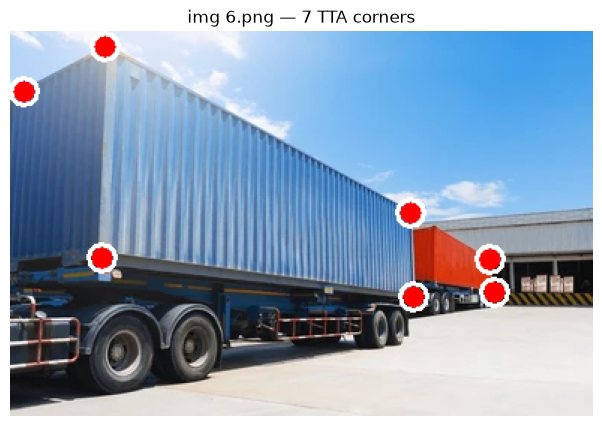

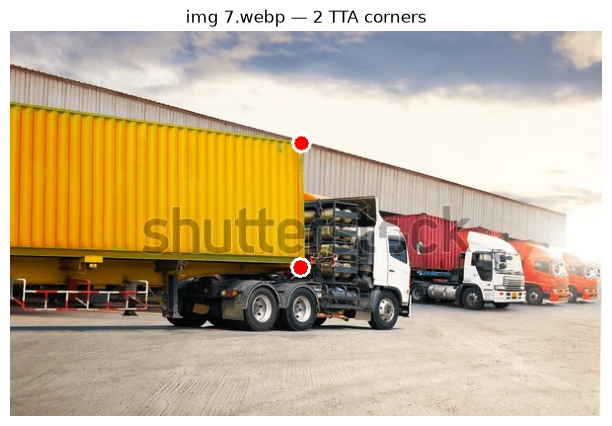

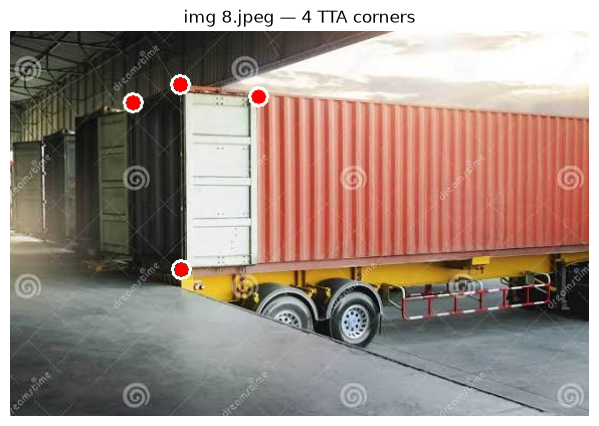

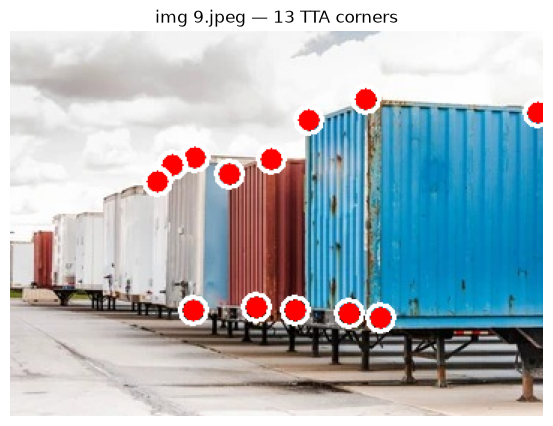

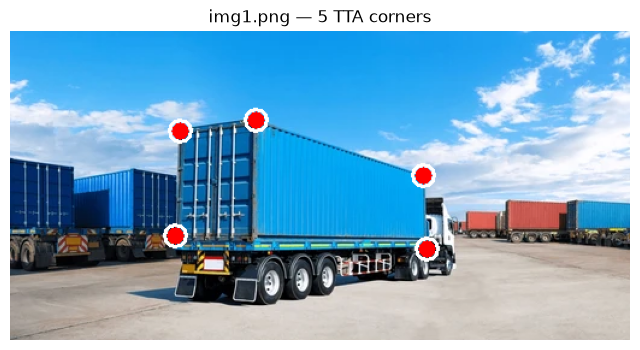

In [8]:
import os, glob, cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
import matplotlib.pyplot as plt

IMG_SIZE = 512
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class StableCornerNet(nn.Module):
    def __init__(self):
        super().__init__()
        b = models.resnet50(weights=None)
        self.stem0 = nn.Sequential(b.conv1, b.bn1, b.relu)
        self.pool = b.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = b.layer1, b.layer2, b.layer3, b.layer4

        self.lat1 = nn.Sequential(nn.Conv2d(256, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))
        self.lat2 = nn.Sequential(nn.Conv2d(512, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))
        self.lat3 = nn.Sequential(nn.Conv2d(1024, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))
        self.lat4 = nn.Sequential(nn.Conv2d(2048, 64, 1), nn.BatchNorm2d(64), nn.ReLU(True))

        self.up1 = nn.Sequential(nn.ConvTranspose2d(256, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.ReLU(True))
        self.fuse128 = nn.Sequential(nn.Conv2d(128 + 64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(True))
        self.up2 = nn.Sequential(nn.ConvTranspose2d(128, 64, 4, 2, 1), nn.BatchNorm2d(64), nn.ReLU(True))

        self.seg_head = nn.Conv2d(64, 2, 1)
        self.hm_head = nn.Sequential(nn.Conv2d(64, 32, 3, padding=1), nn.ReLU(True), nn.Conv2d(32, 1, 1))

    def forward(self, x):
        s0 = self.stem0(x)
        c1 = self.layer1(self.pool(s0))
        c2 = self.layer2(c1); c3 = self.layer3(c2); c4 = self.layer4(c3)
        p1 = self.lat1(c1)
        p2 = F.interpolate(self.lat2(c2), size=p1.shape[2:], mode="bilinear", align_corners=False)
        p3 = F.interpolate(self.lat3(c3), size=p1.shape[2:], mode="bilinear", align_corners=False)
        p4 = F.interpolate(self.lat4(c4), size=p1.shape[2:], mode="bilinear", align_corners=False)
        f128 = self.fuse128(torch.cat([self.up1(torch.cat([p1, p2, p3, p4], dim=1)), s0], dim=1))
        feat = self.up2(f128)
        return self.seg_head(feat), self.hm_head(feat)

def is_collinear_midpoint(pt, kept_pts, line_tol=6.0):
    px, py = pt
    n = len(kept_pts)
    for i in range(n):
        ax, ay = kept_pts[i]
        for j in range(i + 1, n):
            bx, by = kept_pts[j]
            abx, aby = bx - ax, by - ay
            ab_len2 = abx * abx + aby * aby
            if ab_len2 < 1e-4:
                continue
            t = ((px - ax) * abx + (py - ay) * aby) / ab_len2
            if 0.06 < t < 0.94:
                proj_x, proj_y = ax + t * abx, ay + t * aby
                if np.hypot(px - proj_x, py - proj_y) < line_tol:
                    return True
    return False

@torch.no_grad()
def predict_with_tta(net, inp):
    """Averages original + horizontally flipped predictions to boost glare-washed corners and suppress edge noise."""
    s1, h1 = net(inp)
    p1 = torch.softmax(s1, dim=1)[:, 1:2]
    hm1 = torch.sigmoid(h1)

    inp_flip = torch.flip(inp, dims=[3])
    s2, h2 = net(inp_flip)
    p2 = torch.flip(torch.softmax(s2, dim=1)[:, 1:2], dims=[3])
    hm2 = torch.flip(torch.sigmoid(h2), dims=[3])

    seg_prob = 0.5 * (p1 + p2)
    hm_prob = 0.5 * (hm1 + hm2)
    return seg_prob, hm_prob

@torch.no_grad()
def extract_tta_adaptive_corners(seg_prob, hm_prob, base_thresh=0.22, min_dist=24.0, min_area_ratio=0.005):
    raw_mask = (seg_prob.squeeze().cpu().numpy() > 0.42).astype(np.uint8)
    clean_mask = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (7, 7)))

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(clean_mask, connectivity=8)
    min_pixels = int(IMG_SIZE * IMG_SIZE * min_area_ratio)

    hm_np = hm_prob[0, 0].cpu().numpy()
    local_max = F.max_pool2d(hm_prob, kernel_size=13, stride=1, padding=6)
    local_avg = F.avg_pool2d(hm_prob, kernel_size=13, stride=1, padding=6)
    is_peak_map = ((hm_prob == local_max) & ((hm_prob - local_avg) > 0.065))[0, 0].cpu().numpy()

    candidates = []
    for cid in range(1, num_labels):
        if stats[cid, cv2.CC_STAT_AREA] < min_pixels:
            continue
        comp_mask = (labels == cid).astype(np.uint8)
        comp_dil = cv2.dilate(comp_mask, cv2.getStructuringElement(cv2.MORPH_RECT, (15, 15)))

        comp_hm = hm_np * comp_dil
        comp_max = float(comp_hm.max())
        if comp_max < base_thresh:
            continue

        # Adaptive per-container threshold: rescues glare-washed containers without over-triggering bright ones
        comp_thresh = max(base_thresh, 0.38 * comp_max)
        ys, xs = np.where(is_peak_map & (comp_dil > 0) & (hm_np >= comp_thresh))
        for x, y in zip(xs, ys):
            candidates.append((float(hm_np[y, x]), int(x), int(y)))

    # Sort globally strongest peaks first
    candidates.sort(key=lambda item: item[0], reverse=True)

    kept = []
    for score, x, y in candidates:
        x0, x1 = max(0, x - 2), min(IMG_SIZE, x + 3)
        y0, y1 = max(0, y - 2), min(IMG_SIZE, y + 3)
        patch = hm_np[y0:y1, x0:x1]
        gy, gx = np.mgrid[y0:y1, x0:x1]
        w_sum = patch.sum() + 1e-6
        sub_x = float((patch * gx).sum() / w_sum)
        sub_y = float((patch * gy).sum() / w_sum)

        if any(np.hypot(sub_x - kx, sub_y - ky) < min_dist for kx, ky in kept):
            continue
        if is_collinear_midpoint((sub_x, sub_y), kept, line_tol=6.0):
            continue
        kept.append((sub_x, sub_y))

    return np.array(kept, dtype=np.float32)

net = StableCornerNet().to(DEVICE)
net.load_state_dict(torch.load("checkpoints/stable_corner_net_512.pth", map_location=DEVICE))
net.eval()

OUTPUT_DIR = "test_random_512_tta"
os.makedirs(OUTPUT_DIR, exist_ok=True)
mean_rgb = np.array([0.485, 0.456, 0.406], dtype=np.float32)
std_rgb = np.array([0.229, 0.224, 0.225], dtype=np.float32)

for path in sorted(glob.glob(os.path.join("test_random", "*.*"))):
    bgr = cv2.imread(path)
    if bgr is None:
        continue
    bgr_clean = bgr[:int(bgr.shape[0] * 0.92), :]
    ch, cw = bgr_clean.shape[:2]

    rgb = cv2.cvtColor(bgr_clean, cv2.COLOR_BGR2RGB)
    resized = cv2.resize(rgb, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_LINEAR)
    tensor = ((resized.astype(np.float32) / 255.0 - mean_rgb) / std_rgb).transpose(2, 0, 1)
    inp = torch.from_numpy(tensor).unsqueeze(0).to(DEVICE)

    seg_prob, hm_prob = predict_with_tta(net, inp)
    pred_kpts = extract_tta_adaptive_corners(seg_prob, hm_prob, base_thresh=0.22, min_dist=24.0)

    vis = rgb.copy()
    for x512, y512 in pred_kpts:
        xo = int(round((x512 + 0.5) * cw / IMG_SIZE))
        yo = int(round((y512 + 0.5) * ch / IMG_SIZE))
        cv2.circle(vis, (xo, yo), 7, (255, 0, 0), -1)
        cv2.circle(vis, (xo, yo), 9, (255, 255, 255), 2)

    cv2.imwrite(os.path.join(OUTPUT_DIR, os.path.basename(path)), cv2.cvtColor(vis, cv2.COLOR_RGB2BGR))
    plt.figure(figsize=(8, 5))
    plt.imshow(vis)
    plt.title(f"{os.path.basename(path)} — {len(pred_kpts)} TTA corners")
    plt.axis("off")
    plt.show()